# 🔍 Notebook 4: Phân tích & Xử lý Giá trị Ngoại lệ (Outliers)
## Đề tài: Customer Churn Prediction – Phần phụ trách: Outlier

**Câu hỏi cần trả lời**
1. Dữ liệu có outlier không? Phát hiện bằng phương pháp nào, kết quả ra sao?
2. Những điểm "lạ" (nếu có) là **lỗi dữ liệu** hay **khách hàng thật** → nên xóa, sửa hay giữ?
3. Cách xử lý outlier ảnh hưởng thế nào tới hiệu năng mô hình?
4. Quy trình xử lý có **rò rỉ dữ liệu (data leakage)** không?

**Cấu trúc:** (1) đơn biến → (2) đa biến → (3) kiểm tra logic → (4) thực nghiệm mô hình → (5) kết luận.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..') if os.path.exists('../src') else os.path.abspath('.'))
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
from IPython.display import Image, display

from src.config import FIGURES_DIR, RAW_DATA_PATH
from src.outliers import (prepare_numeric_frame, univariate_outlier_report, multivariate_outlier_flags,
                          profile_flagged_groups, consistency_report, plot_univariate_diagnostics,
                          plot_multivariate_outliers, OUTLIER_REPORT_DIR)

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
df_raw = pd.read_csv(RAW_DATA_PATH)
df = prepare_numeric_frame(df_raw)
print(f'Dữ liệu: {df.shape[0]:,} khách hàng')

Dữ liệu: 7,043 khách hàng


---
## 1. Phát hiện Outlier đơn biến
Dùng 4 quy tắc cho 4 biến số liên tục:

| Quy tắc | Điểm bị coi là outlier khi | Ghi chú |
|:--|:--|:--|
| **IQR 1.5** (Tukey) | ngoài $[Q_1-1.5\,IQR,\ Q_3+1.5\,IQR]$ | quy tắc phổ biến nhất, không giả định phân phối chuẩn |
| **IQR 3.0** | ngoài $[Q_1-3\,IQR,\ Q_3+3\,IQR]$ | chỉ bắt outlier *cực đoan* |
| **Z-score** | $|z| > 3$ | giả định gần chuẩn, nhạy với chính outlier |
| **Modified Z (MAD)** | $|0.6745\,(x-\text{median})/\text{MAD}| > 3.5$ | bền vững hơn Z-score, nhưng *đánh giá quá tay* với phân phối lệch |

In [2]:
uni = univariate_outlier_report(df)
display(uni.round(3).T)

Biến,tenure,MonthlyCharges,TotalCharges,AvgChargePerMonth
Min,0.000,18.250,18.800,9.183
Max,72.000,118.750,8684.800,118.970
Skewness,0.240,-0.221,0.963,-0.008
Kurtosis,-1.387,-1.257,-0.228,-1.289
Hàng rào dưới (1.5 IQR),-60.000,-46.025,-4683.525,-61.808
Hàng rào trên (1.5 IQR),124.000,171.375,8868.675,172.814
IQR 1.5,0.000,0.000,0.000,0.000
IQR 3.0 (cực đoan),0.000,0.000,0.000,0.000
Z-score > 3,0.000,0.000,0.000,0.000
Modified Z > 3.5 (MAD),0.000,0.000,136.000,0.000


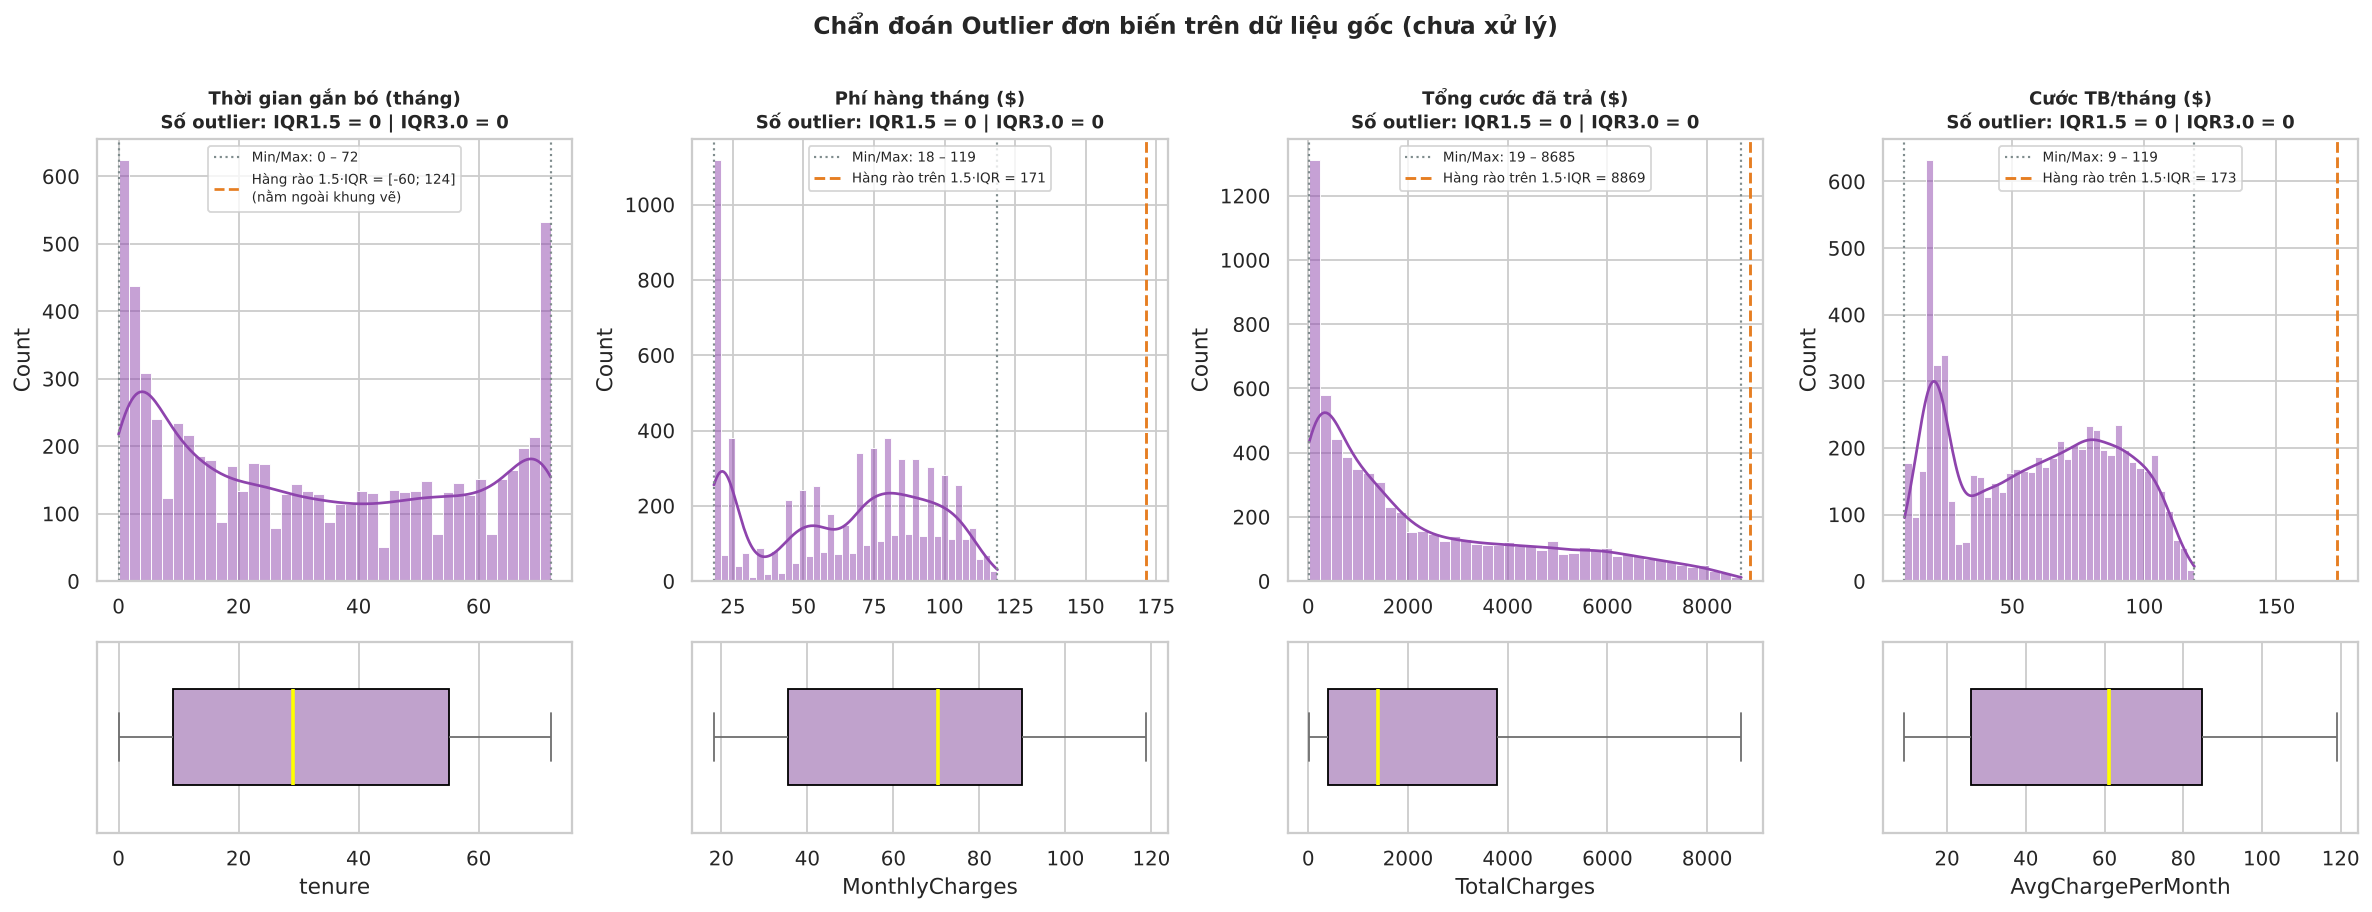

In [3]:
plot_univariate_diagnostics(df, save_path=FIGURES_DIR / '03b_outliers_detection.png')
display(Image(filename=str(FIGURES_DIR / '03b_outliers_detection.png')))

**Nhận xét**
- Cả 4 biến: **0 outlier** theo IQR 1.5, IQR 3.0 và Z-score. Giá trị lớn nhất/nhỏ nhất đều nằm **trong** hàng rào.
- `Modified Z` báo 136 điểm ở `TotalCharges` – đây là **dương tính giả**: `TotalCharges` lệch phải (skewness ≈ 0.96) nên MAD nhỏ so với đuôi phải, các khách trung thành lâu năm bị đánh dấu oan. Không có điểm nào "phi lý" (max = $8,685 ≈ 72 tháng × ~$120).
- `tenure` có giới hạn tự nhiên 0–72 tháng, `MonthlyCharges` bị chặn bởi bảng giá dịch vụ ($18–$119) → **về mặt cấu trúc, dữ liệu không thể có outlier kiểu lỗi nhập liệu cực đoan**.
- Phân phối `tenure` và `MonthlyCharges` có hình *hai đỉnh* (kurtosis âm ≈ −1.3): đây là cấu trúc nhóm khách hàng (mới vs lâu năm; gói rẻ vs gói cao cấp), **không phải** outlier.

---
## 2. Phát hiện Outlier đa biến
Một khách có thể bình thường ở từng biến nhưng **bất thường khi xét cùng lúc** (ví dụ: tenure rất ngắn nhưng `TotalCharges` quá lớn). Dùng 3 thuật toán độc lập trên `tenure`, `MonthlyCharges`, `TotalCharges` (đã chuẩn hóa):
- **Isolation Forest** (contamination 1%): điểm dễ bị "cô lập" bằng ít lần cắt ngẫu nhiên.
- **Local Outlier Factor** (k = 30, contamination 1%): mật độ cục bộ thấp hơn hàng xóm.
- **Mahalanobis robust (MCD)**: khoảng cách có tính tương quan, ngưỡng $\chi^2_{3}$ tại p = 0.999.

In [4]:
flags = multivariate_outlier_flags(df)
profile = profile_flagged_groups(df, flags)
display(profile.round(3))
print('Số khách được cả 3 thuật toán cùng gắn cờ:', int((flags['n_flags'] == 3).sum()))

,Số khách,Tỷ lệ churn,tenure (TB),MonthlyCharges (TB),TotalCharges (TB)
Nhóm,,,,,
Toàn bộ khách hàng,7043,0.265,32.371,64.762,2279.799
Isolation Forest,71,0.085,70.042,114.802,8086.840
LOF,71,0.479,10.324,51.348,700.381
Mahalanobis (MCD),346,0.006,66.197,22.406,1489.690
Được >= 2 thuật toán gắn cờ,7,0.143,65.429,68.364,4337.779


Số khách được cả 3 thuật toán cùng gắn cờ: 0


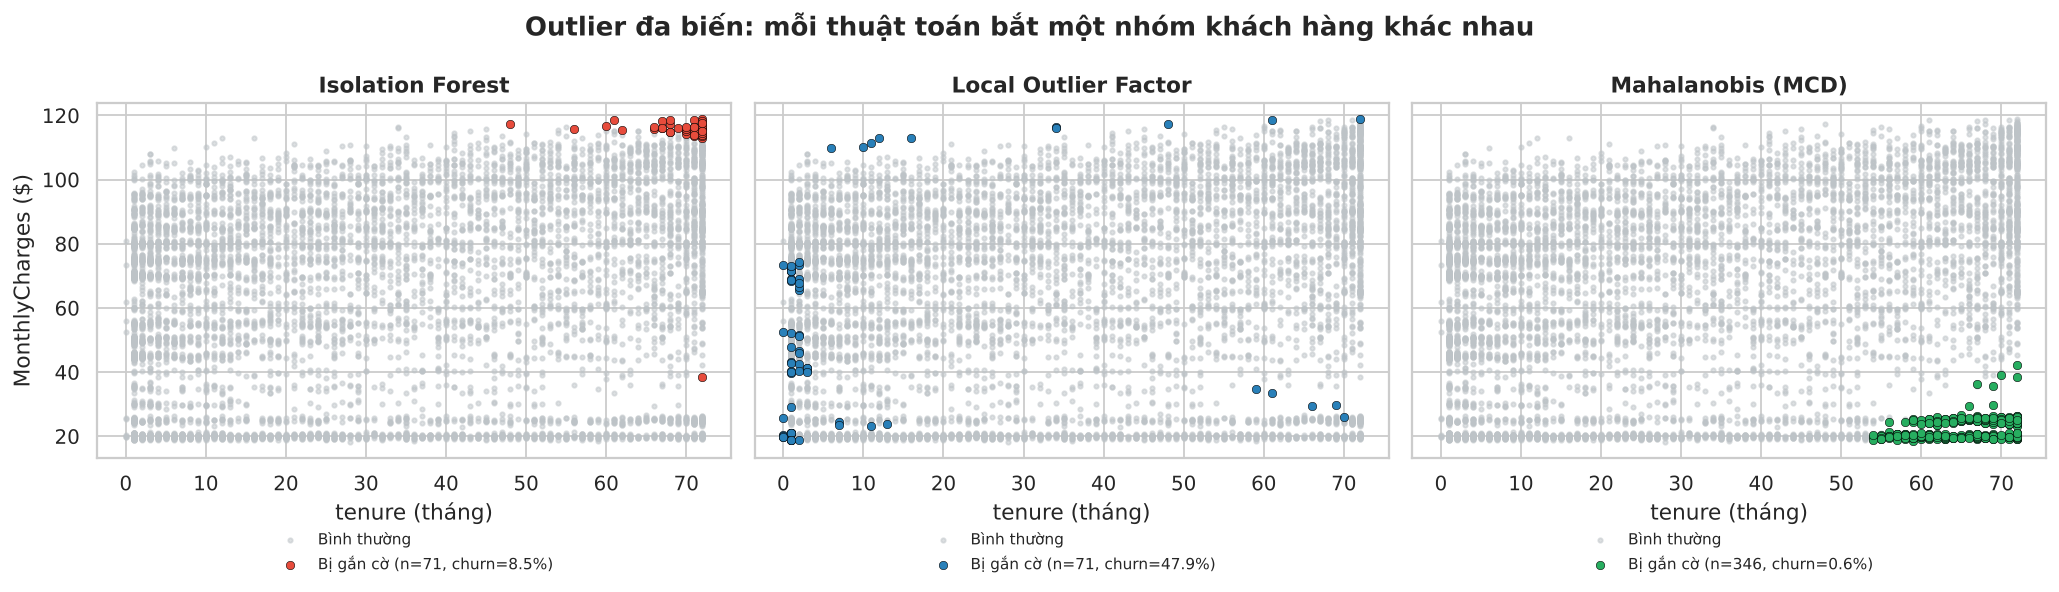

In [5]:
plot_multivariate_outliers(df, flags, save_path=FIGURES_DIR / '03c_multivariate_outliers.png')
display(Image(filename=str(FIGURES_DIR / '03c_multivariate_outliers.png')))

**Nhận xét – 3 thuật toán bắt 3 nhóm *khác nhau* (chỉ 7 khách trùng ≥ 2 thuật toán, không khách nào trùng cả 3):**

| Thuật toán | Nhóm bị gắn cờ | Tỷ lệ churn | Diễn giải |
|:--|:--|:-:|:--|
| Isolation Forest | tenure ≈ 70 tháng, cước ≈ \$115 | **8.5%** | Khách VIP lâu năm dùng gói cao cấp, trung thành hơn mức chung (26.5%) |
| LOF | chủ yếu tenure 0–3 tháng, cước trung bình | **47.9%** | Khách mới ở vùng thưa mật độ; rủi ro rời bỏ cao gần gấp đôi |
| Mahalanobis | tenure ≈ 66, cước ≈ \$22 | **0.6%** | Khách lâu năm chỉ dùng điện thoại/gói rẻ, gần như không rời đi |

Đây đều là **các phân khúc khách hàng thật có ý nghĩa kinh doanh**, và tỷ lệ churn của chúng khác hẳn mức trung bình – xóa chúng sẽ **làm mất đúng những tín hiệu mà mô hình cần học**.

---
## 3. Kiểm tra tính nhất quán (phát hiện lỗi nhập liệu)
Nếu có outlier do lỗi, nó thường vi phạm logic nghiệp vụ. Kiểm tra: $\text{TotalCharges} \approx \text{tenure} \times \text{MonthlyCharges}$ (cho phép lệch do khách đổi gói).

In [6]:
cons = consistency_report(df)
pd.Series(cons).to_frame('Giá trị')

,Giá trị
Số dòng trùng lặp,0.000000
Số giá trị âm (tenure/MonthlyCharges/TotalCharges),0.000000
Số dòng tenure = 0,11.000000
tenure vượt 72 tháng,0.000000
Tỷ lệ TotalCharges / (tenure x MonthlyCharges): min,0.689356
Tỷ lệ ...: trung vị,1.000000
Tỷ lệ ...: max,1.573454
Số dòng tỷ lệ < 0.5 hoặc > 2 (nghi lỗi nhập liệu),0.000000
"Số dòng tỷ lệ ngoài hàng rào IQR (đổi gói cước, hợp lý)",617.000000


**Nhận xét**
- Không có dòng trùng, không giá trị âm, không `tenure` > 72.
- Tỷ lệ `TotalCharges / (tenure × MonthlyCharges)` nằm trong **[0.69; 1.57]**, trung vị = 1.00 → **không có dòng nào vô lý** (ngưỡng nghi lỗi: < 0.5 hoặc > 2 → 0 dòng).
- 617 dòng lệch khỏi 1.0 theo IQR là do khách **đổi gói cước giữa chừng** (hợp lý), không phải lỗi.
- 11 dòng `tenure = 0` đã được xử lý riêng ở phần MAR.

---
## 4. Thực nghiệm: cách xử lý outlier ảnh hưởng thế nào tới mô hình?
**Thiết kế (chống rò rỉ dữ liệu):** lặp **10 lần** chia train/test (stratified 80/20, seed khác nhau). Mỗi lần: ngưỡng/bộ lọc **học trên train**, áp lên test, test **luôn nguyên vẹn**. So sánh 8 phương án × 3 mô hình, báo cáo ROC-AUC trung bình ± SD và kiểm định t **ghép cặp** so với baseline.

Kết quả được tạo bởi `python run_outliers.py` (≈ 4 phút) và đọc từ `reports/outlier_analysis/`.

In [7]:
summary = pd.read_csv(OUTLIER_REPORT_DIR / '04_experiment_summary.csv')
view = summary[['Mô hình','Phương pháp','AUC_mean','AUC_std','Recall_mean','F1_mean','ΔAUC vs baseline','p-value (ghép cặp)']]
display(view.round(4).style.hide(axis='index'))

Mô hình,Phương pháp,AUC_mean,AUC_std,Recall_mean,F1_mean,ΔAUC vs baseline,p-value (ghép cặp)
Gradient Boosting,A. Không xử lý (baseline),0.841900,0.012800,0.517100,0.573800,0.000000,1.000000
Gradient Boosting,B. Capping IQR 1.5 (cách đang dùng),0.841900,0.012800,0.517100,0.573800,0.000000,1.000000
Gradient Boosting,C. Winsorize 1% - 99%,0.842200,0.013100,0.515000,0.573300,0.000300,0.341400
Gradient Boosting,D. Winsorize 5% - 95%,0.842500,0.013400,0.516800,0.575000,0.000600,0.224800
Gradient Boosting,E. Loại outlier Isolation Forest (train),0.839500,0.013300,0.513400,0.569000,-0.002400,0.043000
Gradient Boosting,F. Loại outlier LOF (train),0.842100,0.013300,0.516800,0.575100,0.000200,0.566600
Gradient Boosting,G. log1p(TotalCharges),0.841900,0.012800,0.517100,0.573800,-0.000000,0.120800
Gradient Boosting,H. RobustScaler thay StandardScaler,0.841900,0.012800,0.517100,0.573800,0.000000,0.129800
Logistic Regression,A. Không xử lý (baseline),0.845900,0.013100,0.797900,0.630100,0.000000,1.000000
Logistic Regression,B. Capping IQR 1.5 (cách đang dùng),0.845900,0.013100,0.797900,0.630100,0.000000,1.000000


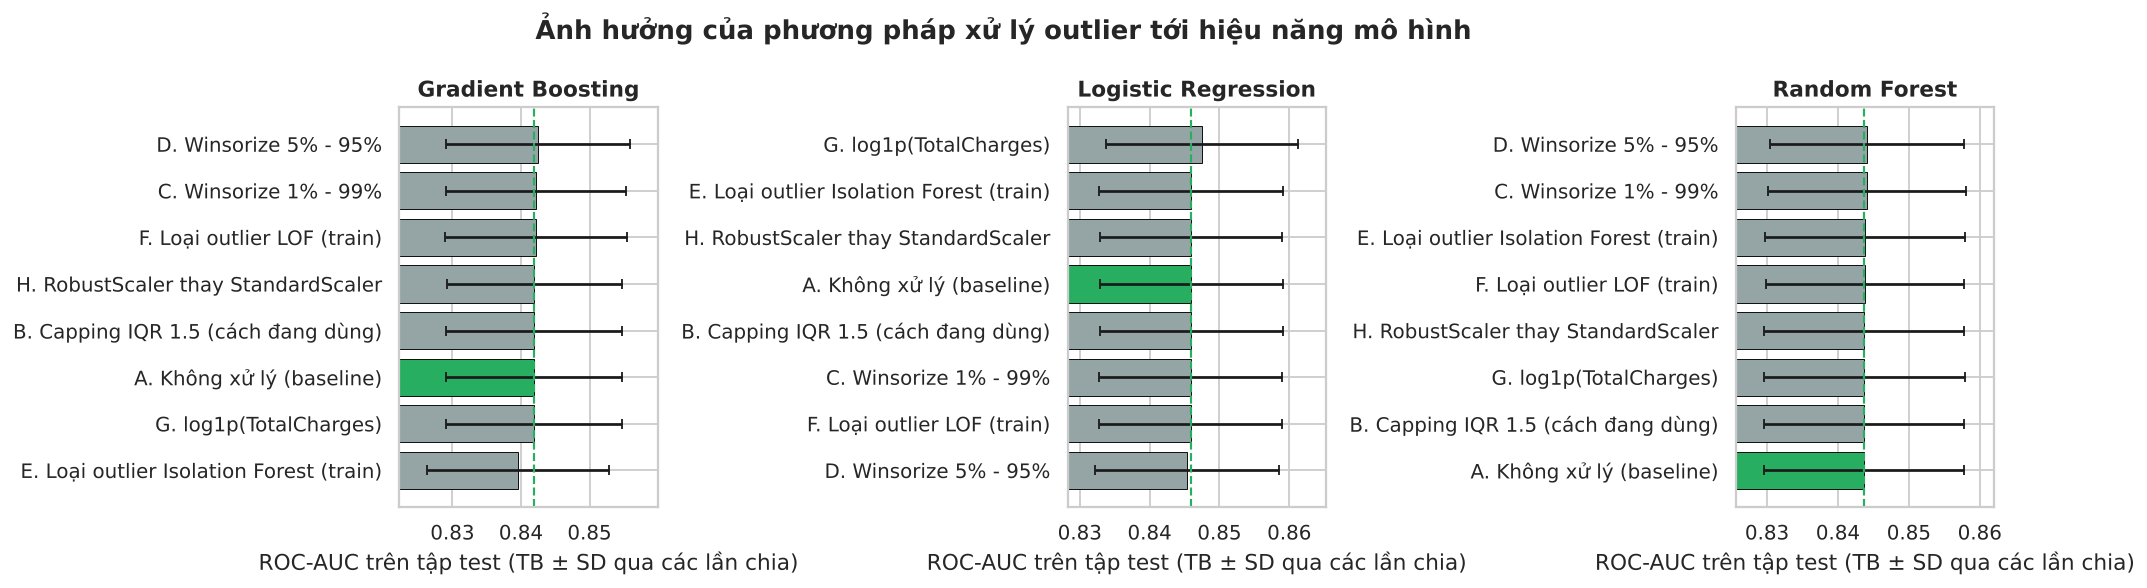

In [8]:
display(Image(filename=str(FIGURES_DIR / '03d_outlier_treatment_comparison.png')))

**Nhận xét**
1. **Capping IQR 1.5 (cách đang dùng) giống baseline tuyệt đối** (ΔAUC = 0.0000, mọi mô hình) → xác nhận bước này không thay đổi dữ liệu vì không có outlier.
2. Mọi phương án có |ΔAUC| < 0.003, **nhỏ hơn ~5 lần so với độ dao động giữa các lần chia (SD ≈ 0.013)** → khác biệt không có ý nghĩa thực tiễn.
3. Loại outlier bằng Isolation Forest làm **giảm** AUC của Gradient Boosting (−0.0024, p = 0.043, không còn ý nghĩa sau hiệu chỉnh đa so sánh) → xác nhận *không nên xóa* nhóm VIP.
4. Winsorize 5%–95% làm Logistic Regression **giảm** nhẹ (−0.0006): cắt bớt thông tin hợp lệ.
5. Điểm duy nhất tích cực: `log1p(TotalCharges)` cho Logistic Regression **+0.0016 AUC** (p = 0.0025), do `TotalCharges` lệch phải; mô hình cây không bị ảnh hưởng. Đây là xử lý *độ lệch phân phối*, không phải xử lý outlier.

> ⚠️ p-value tính từ 10 lần chia dữ liệu chồng lấn nên **lạc quan**; 21 phép so sánh cần hiệu chỉnh (Bonferroni: ngưỡng ≈ 0.0024). Vì vậy chỉ coi là gợi ý.

---
## 5. Kết luận & Quyết định xử lý

| Câu hỏi | Kết luận |
|:--|:--|
| Có outlier không? | **Không có outlier đơn biến** (IQR 1.5/3.0, Z-score đều = 0). Outlier đa biến chỉ là các phân khúc khách hàng hợp lệ. |
| Có lỗi dữ liệu không? | **Không**: không trùng lặp, không âm, `TotalCharges` khớp `tenure × MonthlyCharges` (tỷ lệ 0.69–1.57). |
| Xóa hay giữ? | **Giữ toàn bộ 7,043 khách hàng.** Xóa sẽ mất tín hiệu churn (nhóm LOF churn 47.9%) và không cải thiện mô hình. |
| Capping IQR | **Giữ như chốt an toàn** (không đổi giá trị nào trên dữ liệu hiện tại, bảo vệ pipeline nếu có dữ liệu mới). |
| Rò rỉ dữ liệu | `handle_outliers` trong pipeline tính ngưỡng trên toàn bộ dữ liệu trước khi chia; vì không cắt điểm nào nên **không ảnh hưởng kết quả**, nhưng khi tái sử dụng nên dùng `OutlierCapper` (fit trên train). |
| Khuyến nghị tùy chọn | Dùng `log1p(TotalCharges)` cho Logistic Regression (+0.0016 AUC). Cần cả nhóm đồng ý vì thay đổi feature chung. |

**Thông điệp cho báo cáo:** *"Chúng tôi đã kiểm tra outlier bằng 7 phương pháp (đơn biến, đa biến, logic nghiệp vụ) và kiểm chứng bằng thực nghiệm; dữ liệu Telco không chứa outlier cần loại bỏ, nên toàn bộ mẫu được giữ lại."*